# W6D2 — RAG: Give the LLM a Cheat Sheet — Lab

**Week 6 · Day 2 · LLMs** · Lab

> A chatbot can't answer questions about documents it has never seen.
> So before we ask it, we **find the right paragraph and paste it into the question**.
> That is **RAG** (Retrieval-Augmented Generation).

It is an **open-book exam**: the student (the LLM) doesn't remember the answer,
but if you open the book at the right page, they can read it and answer.

<div dir="rtl" align="right">

> النموذج لا يستطيع الإجابة عن مستندات لم يرها. لذلك قبل أن نسأله **نبحث عن الفقرة
> الصحيحة ونلصقها داخل السؤال**. هذا هو **RAG**.

إنه **امتحان كتاب مفتوح**: الطالب (النموذج) لا يتذكّر الإجابة، لكن إذا فتحتَ الكتاب على
الصفحة الصحيحة يقرأ ويُجيب.

</div>

> **This is your lab notebook.** Work through the hints — they tell you what to do and where
> to look, not what to type. Stuck for more than ten minutes on one task? Open the `_guided`
> version. That is not cheating; sitting stuck in silence is the only mistake. The full
> solution is released at the end of the day.

<div dir="rtl" align="right">

> **هذا دفتر المعمل الخاص بك.** اعمل وفق الإرشادات — فهي تخبرك بما يجب فعله وأين تبحث، لا بما
> تكتبه حرفيًا. إذا توقّفت أكثر من عشر دقائق عند مهمة واحدة فافتح نسخة `_guided`؛ هذا ليس غشًّا،
> والخطأ الوحيد هو أن تبقى متوقّفًا بصمت. ويُنشر الحل الكامل في نهاية اليوم.

</div>

### The whole idea in one picture

```
  WITHOUT RAG                         WITH RAG

  Question ──► LLM ──► guess          Question ──► 1. FIND  ──► 2. PASTE ──► 3. ASK ──► Answer
                                                   best        paragraphs    the LLM
                                                   paragraphs  + question
                                                   from our
                                                   documents
```

<div dir="rtl" align="right">

### الفكرة كلها في صورة

بدون RAG: السؤال ← النموذج ← تخمين. مع RAG: السؤال ← **١. ابحث** عن أفضل الفقرات ←
**٢. الصق** الفقرات مع السؤال ← **٣. اسأل** النموذج ← الإجابة.

</div>

## Setup

Two small free models run on your machine: an **embedder** (turns text into numbers)
and an **LLM** (writes answers). This cell also defines two helpers you will just *use*:

- `embed(text)` → numbers that capture the **meaning** of the text.
- `chat(prompt)` → the LLM's answer.

First run downloads ~700 MB. Nothing to write, just run it.

<div dir="rtl" align="right">

## الإعداد

نموذجان صغيران مجانيان: **مُضمِّن** (يحوّل النصّ إلى أرقام) و**نموذج لغوي** (يكتب
الإجابات). تُعرّف هذه الخلية أداتين ستستخدمهما فقط: `embed` (أرقام تمثّل المعنى) و`chat`
(إجابة النموذج). لا شيء تكتبه، شغّلها.

</div>

In [1]:
# === Setup: load models and define embed() and chat() ==============================
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "transformers>=4.40", "sentence-transformers>=3.0", "accelerate"])

import torch, numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from sentence_transformers import SentenceTransformer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
embedder  = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device=DEVICE)
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
llm       = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct").to(DEVICE).eval()

def embed(texts):
    """text (or list of texts) -> numbers, one row per text"""
    if isinstance(texts, str):
        texts = [texts]
    return embedder.encode(texts, normalize_embeddings=True, show_progress_bar=False)

@torch.no_grad()
def chat(prompt):
    """prompt -> the LLM's answer"""
    msgs = [{"role": "system", "content": "Answer in one or two short sentences."},
            {"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    enc = tokenizer(text, return_tensors="pt").to(DEVICE)
    out = llm.generate(**enc, max_new_tokens=100, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print("ready on", DEVICE)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

ready on cuda


## Section 1 — Meaning as numbers

`embed` turns a sentence into 384 numbers. Sentences with a **similar meaning** get
**similar numbers**. We compare two sentences with a dot product `a @ b`:
**higher score = closer meaning**. This is the only "AI" in searching.

<div dir="rtl" align="right">

## القسم ١ — المعنى كأرقام

`embed` تحوّل الجملة إلى ٣٨٤ رقمًا. الجمل **المتقاربة في المعنى** تأخذ أرقامًا **متقاربة**.
نقارن جملتين بضرب نقطي `a @ b`: **درجة أعلى = معنى أقرب**. هذا هو «الذكاء» الوحيد في البحث.

</div>

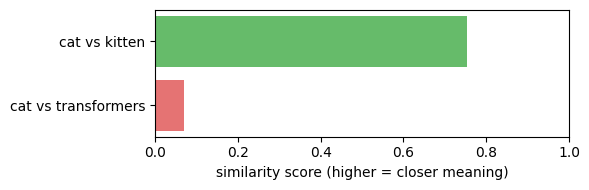

In [2]:
# === Demo: similar meaning -> high score ===========================================
sentences = ["A cat sits on the mat.", "A kitten rests on the rug.", "Transformers process sequences."]
vecs = embed(sentences)
scores = [float(vecs[0] @ v) for v in vecs[1:]]

plt.figure(figsize=(6, 2))
plt.barh(["cat vs transformers", "cat vs kitten"], scores[::-1], color=["#e57373", "#66bb6a"])
plt.xlim(0, 1); plt.xlabel("similarity score (higher = closer meaning)")
plt.tight_layout(); plt.show()

## Section 2 — The problem

Our "library": **10 made-up paragraphs** from an imaginary *Olo Academy Handbook*.
No LLM has ever seen them. Let's ask the LLM about one anyway.

<div dir="rtl" align="right">

## القسم ٢ — المشكلة

«مكتبتنا»: **١٠ فقرات مخترعة** من *دليل أكاديمية علو*. لم يرها أي نموذج. لنسأل النموذج
عن إحداها.

</div>

In [3]:
# === Our 10 made-up paragraphs, and a question the LLM cannot know =================
DOCS = [
    "The AI Engineering Bootcamp (AIEP) at Olo Academy is an 8-week program covering foundations, data engineering, neural networks, CNNs, NLP, LLMs, retrieval, and a final capstone.",
    "Students get a certificate only if they submit all 5 weekly projects and the final capstone with a passing grade.",
    "The Online TA of AIEP is Mohammed Bremoo. He holds office hours every Tuesday from 10 AM to 2 PM Riyadh time.",
    "Lab notebooks run on Google Colab or locally in VSCode with the shared AIEP conda environment. GPU access comes from Colab's free T4 tier.",
    "The October 2026 cohort is limited to 40 students. Applications close one week before the start date and needrequire a short technical interview.",
    "The capstone project runs in week 8 and is presented live on the final Thursday to a panel of three industry mentors.",
    "Olo Academy was founded in 2024 and is based in Riyadh, Saudi Arabia. It teaches only applied AI engineering.",
    "Students should do about 20 hours of self-study per week, on top of 15 hours of live classes and labs.",
    "The Olo Academy Discord is the main place for peer support. Instructors watch the #help channel from 9 AM to 9 PM Riyadh time every day.",
    "Attendance below 70% of live sessions means automatic removal from the program, whatever your project grades are. No exceptions.",
]
DOC_VECTORS = embed(DOCS)   # every paragraph turned into numbers, once
QUESTION = "What are the office hours of the AIEP Online TA?"
print("Without RAG:", chat(QUESTION))

Without RAG: I'm sorry, but I don't have access to specific information about the AIEP Online TA's office hours as it might vary depending on the institution and their policies. You may want to check with your institution directly for the most accurate and up-to-date information.


It can't know (the answer is in paragraph 2). It guesses or gives up. Now we fix that
in **two small tasks**.

<div dir="rtl" align="right">

لا يستطيع أن يعرف (الإجابة في الفقرة ٢). يخمّن أو يستسلم. سنصلح ذلك في **مهمتين صغيرتين**.

</div>

## Task 1 — FIND: `search(question, k)`

Return the `k` paragraphs closest in meaning to the question, best first.
Two steps: **score** every paragraph, then **take the top `k`**.

<div dir="rtl" align="right">

## المهمة ١ — ابحث: `search(question, k)`

أرجع الـ`k` فقرات الأقرب في المعنى إلى السؤال، الأفضل أولًا. خطوتان: **أعطِ** كل فقرة درجة،
ثم **خذ** أعلى `k`.

</div>

In [14]:
# ────────────────────────────────────────────────────────────────────
# 1) scores = DOC_VECTORS @ embed(question)[0]   -> one score per paragraph
# 2) best = np.argsort(scores)[::-1][:k]   -> positions of the k highest scores
# 3) return [DOCS[i] for i in best]
#
# ١) scores = DOC_VECTORS @ embed(question)[0]   -> درجة لكل فقرة
# ٢) best = np.argsort(scores)[::-1][:k]   -> مواضع أعلى k درجات
# ٣) return [DOCS[i] for i in best]
# ────────────────────────────────────────────────────────────────────
# === Task 1 — FIND: retrieve the k most relevant paragraphs =======================
def search(question, k=2):
    scores = DOC_VECTORS @ embed(question)[0]
    best = np.argsort(scores)[::-1][:k]
    return [DOCS[i] for i in best]

# Quick check: the paragraph about the TA's office hours should appear first.
print("Top paragraph:", search(QUESTION, k=1)[0])



Top paragraph: The Online TA of AIEP is Mohammed Bremoo. He holds office hours every Tuesday from 10 AM to 2 PM Riyadh time.


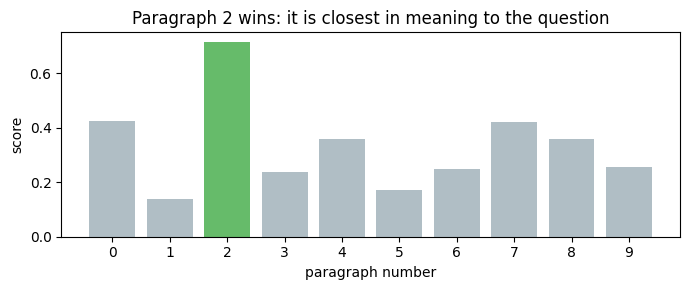

In [10]:
# === Picture: how well does each paragraph match the question? =====================
scores = DOC_VECTORS @ embed(QUESTION)[0]
plt.figure(figsize=(7, 3))
plt.bar(range(len(DOCS)), scores, color=["#66bb6a" if s == scores.max() else "#b0bec5" for s in scores])
plt.xticks(range(len(DOCS))); plt.xlabel("paragraph number"); plt.ylabel("score")
plt.title("Paragraph 2 wins: it is closest in meaning to the question")
plt.tight_layout(); plt.show()

## Task 2 — PASTE and ASK: `ask(question, k)`

The prompt template `PROMPT` (below) already has three parts. Fill in the paragraphs and the question, then send it to the LLM:

```
Use ONLY the text below to answer. If the answer is not there, say "I don't know".

Text:
<the k paragraphs from search>

Question: <the question>
```

<div dir="rtl" align="right">

## المهمة ٢ — الصق واسأل: `ask(question, k)`

ابنِ مُحثًّا من ثلاثة أجزاء (التعليمة، النصّ الذي وجدناه، السؤال) ثم أرسله إلى النموذج.

</div>

In [8]:
# ────────────────────────────────────────────────────────────────────
# 1) paragraphs = search(question, k)
# 2) text = "\n".join(paragraphs)   (glue the paragraphs into one string)
# 3) return chat(PROMPT.format(text=text, question=question))
#
# ١) paragraphs = search(question, k)
# ٢) text = "\n".join(paragraphs)   (ألصق الفقرات في نصّ واحد)
# ٣) return chat(PROMPT.format(text=text, question=question))
# ────────────────────────────────────────────────────────────────────
# === Task 2 — PASTE and ASK: answer using retrieved context =======================
PROMPT = """Use ONLY the text below to answer. If the answer is not there, say "I don't know".

Text:
{text}

Question: {question}"""

def ask(question, k=3):
    paragraphs = search(question, k)
    text = "\n".join(paragraphs)
    return chat(PROMPT.format(text=text, question=question))

# Quick check: generate an answer grounded in the retrieved paragraphs.
print("With RAG:", ask(QUESTION))


With RAG: The Online TA of AIEP is Mohammed Bremoo. He holds office hours every Tuesday from 10 AM to 2 PM Riyadh time.


## Section 3 — Before and after

Same LLM, same question. Only the pasted paragraphs differ.

<div dir="rtl" align="right">

## القسم ٣ — قبل وبعد

النموذج نفسه والسؤال نفسه. الفرق الوحيد هو الفقرات الملصقة.

</div>

In [11]:
# === Before vs after ===============================================================
for q in ["How many students are in the October 2026 cohort?",
          "What happens if my attendance is below 70%?"]:
    print("Q:", q)
    print("  without RAG:", chat(q))
    print("  with RAG   :", ask(q))
    print()

Q: How many students are in the October 2026 cohort?
  without RAG: I'm sorry, but I don't have access to real-time information about student numbers for specific cohorts. To get accurate and up-to-date data on the number of students in a particular year's cohort, you would need to check with your school or educational institution directly. They should be able to provide this information through their official website or contact them via email.
  with RAG   : There are 40 students in the October 2026 cohort.

Q: What happens if my attendance is below 70%?
  without RAG: If your attendance rate falls below 70%, it could indicate that you are not meeting the minimum required standards for participation and may need to consider additional support or adjustments to ensure a balanced workload and effective learning environment.
  with RAG   : If your attendance is below 70%, you will be automatically removed from the program, regardless of your project grades.



## Section 4 — When the answer is not in the documents

`search` always returns the top `k`, even when nothing matches. It can't tell
"good match" from "best of a bad lot". So the **"say I don't know"** line in the
prompt is what protects you. Try it:

<div dir="rtl" align="right">

## القسم ٤ — عندما تكون الإجابة غير موجودة

`search` تُرجع دائمًا أعلى `k` حتى لو لم يتطابق شيء؛ لا تفرّق بين «مطابقة جيدة» و«أفضل
الموجود السيّئ». لذلك تحميك جملة **«قل لا أعلم»** في المُحثّ. جرّب:

</div>

In [12]:
# === Question that is NOT in the handbook ==========================================
# NOT_IN_DOCS = "How much does the AIEP program cost in Saudi Riyals?"
NOT_IN_DOCS = "Is Iyas Baroud the lead instructor?"
print("Answer:", ask(NOT_IN_DOCS))
print("\nIt was given:")
for paragraph in search(NOT_IN_DOCS):
    print("-", paragraph)

Answer: No, Iyas Baroud is not mentioned as the lead instructor at the Olo Academy Discord.

It was given:
- The Olo Academy Discord is the main place for peer support. Instructors watch the #help channel from 9 AM to 9 PM Riyadh time every day.
- The capstone project runs in week 8 and is presented live on the final Thursday to a panel of three industry mentors.


## Wrap-up

| Function | Job |
|---|---|
| `embed` | text → numbers (meaning) |
| `search` | question → best paragraphs |
| `ask` | search → paste → LLM answers |

**RAG does not make the LLM smarter. It changes what the LLM has in front of it.**
Also remember: `k` too big means noise and a slower prompt, and if the answer isn't in
your documents the LLM may still guess.

**Next (D3):** we give the LLM **tools to use** (calculator, search). That is an **agent**.

<div dir="rtl" align="right">

## الخلاصة

`embed` (نصّ ← أرقام تمثّل المعنى)، `search` (سؤال ← أفضل الفقرات)، `ask` (ابحث ← الصق ←
النموذج يُجيب).

**RAG لا يجعل النموذج أذكى؛ هو يغيّر ما أمامه.** وتذكّر: `k` الكبير يعني ضوضاء وبطئًا،
وإذا لم تكن الإجابة في مستنداتك فقد يخمّن النموذج.

**التالي (D3):** نعطي النموذج **أدوات يستعملها**. هذا هو **الوكيل**.

</div>